# Applied Statistics In Machine Learning

Now that we've introduced statistical concepts we'll now focus on some of the motivation behind why we might apply these in machine learning in particular we will looks at the ***feature selection*** process

Contrary to popular belief, adding more feature to your dataset doesn't always make your model better. In fact, adding irrelevant features can actually make your model worse on future data it hasn't seen yet. This is because of a concept called the **Bias-Variance Tradeoff**.

## Bias-Variance Tradeoff

The **Bias-Variance Trade-off** is the balance between a model being too simple or too complex.

---

### 1. Underfitting (High Bias)

The model is too simple to capture the underlying pattern.

* **The Cause:** Using a "stiff" model (like a straight line) for curved data.
* **The Result:** High error on both training and new data because the model misses the point entirely.

### 2. Overfitting (High Variance)

The model is too flexible and "memorizes" the data, including random noise.

* **The Cause:** Using a highly complex model that tries to touch every single data point.
* **The Result:** Perfect accuracy on training data, but fails on new data because it learned patterns
that don't actually exist.


### 3. The Trade-off

You cannot minimize both bias and variance simultaneously; as one goes down, the other typically goes up.

| Feature | Underfitting (High Bias) | Overfitting (High Variance) |
| --- | --- | --- |
| **Model Shape** | Too simple (Straight line) | Too complex (Wiggly curve) |
| **Training Data** | High error | Near-zero error |
| **New Data** | High error | High error |
| **Solution** | Add more features/complexity | **Feature Selection** / Regularization |

---



![image.png](attachment:image.png)

# Non-Parametric Tests vs Parametric Tests


---

### The Core Difference

* **Parametric Tests:** Assume your data follows a specific "shape" (usually a **Normal Distribution** or Bell Curve). They calculate specific "parameters" like the average (mean) and spread (variance).
* **Non-parametric Tests:** "Distribution-free" tests. They don't care about the shape of your data and often use the **rank** (1st, 2nd, 3rd) of the values instead of the actual numbers.

---

### Comparison Table

| Feature | Parametric Tests | Non-parametric Tests |
| --- | --- | --- |
| **Data Assumption** | Assumes a Normal/Bell Curve. | No assumptions about data shape. |
| **Data Type** | Best for continuous, clean numbers. | Best for "messy" data or rankings. |
| **Sensitivity** | Highly precise with "perfect" data. | Robust; works well with outliers. |
| **Typical Goal** | Compare means (averages). | Compare medians or ranks. |
| **Examples** | Pearson Correlation, ANOVA | Spearman Correlation, Chi-Square. |

---

### When to use which?

1. **Use Parametric** if your data looks symmetrical and follows a bell curve. These are more "powerful" at finding subtle relationships between features.
2. **Use Non-parametric** if your data is skewed, has extreme outliers
---


# Scatter Plots - Pearson's vs Spearman's Correlation

- Depicts the relationship between two continuous variables


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Generate 50 points: X is linear, Y is exponential
x = np.linspace(1, 10, 50)
# y = 3^x + small noise (to keep it realistic)
y = (3**x) + np.random.normal(0, 100, 50)

df = pd.DataFrame({'Time_Weeks': x, 'Growth_Users': y})

In [ ]:
df.head()

,Time_Weeks,Growth_Users
0,1.000000,-81.679372
1,1.183673,-147.813964
2,1.367347,-40.160007
3,1.551020,91.135602
4,1.734694,28.133864


In [ ]:
df.corr(method='pearson')

,Time_Weeks,Growth_Users
Time_Weeks,1.000000,0.692119
Growth_Users,0.692119,1.000000


In [ ]:
df.corr(method='spearman')

,Time_Weeks,Growth_Users
Time_Weeks,1.000000,0.971765
Growth_Users,0.971765,1.000000


Why are are the two correlations so different?

# Pearson's:
-  **Assumptions**: Linear relationship between variables,
                Normally distributed variables

<Axes: xlabel='Time_Weeks', ylabel='Growth_Users'>

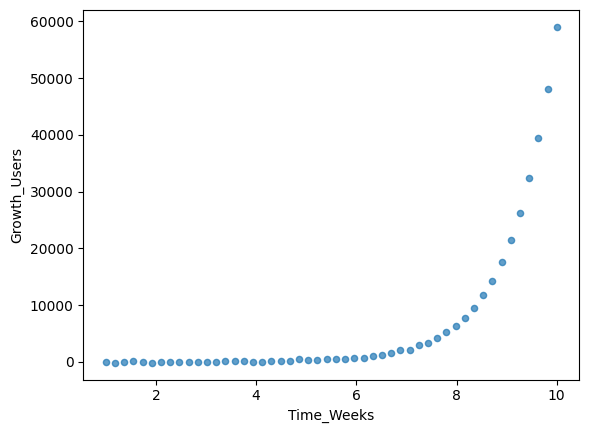

In [ ]:
df.plot.scatter(x='Time_Weeks', y='Growth_Users', alpha=0.7)

### What happened here suddenly the correlation is was moderately strong but there now there is a perfect relationship relationship between the two variables?

- pearson's correlation only captures linear relationships, so if the relationship is non-linear, the correlation can be lower even if there is a strong relationship between the variables. In this case, the relationship between the two variables may be non-linear, which is why the correlation is lower. However, when we look at the scatter plot, we can see that there is a clear pattern or relationship between the two variables, indicating that there is indeed a strong relationship between them.

#  Pearson's vs Spearman's Correlation and Outliers

lets first create a near perfect Correlation and see what happens when we add an outlier to the data

In [ ]:
# 1. Generate Data
np.random.seed(42)
x = np.linspace(1, 50, 50)
y = x + np.random.normal(0, 1, 50)

# 2. Create DataFrame and Calculate Correlations
df = pd.DataFrame({'X': x, 'Y': y})

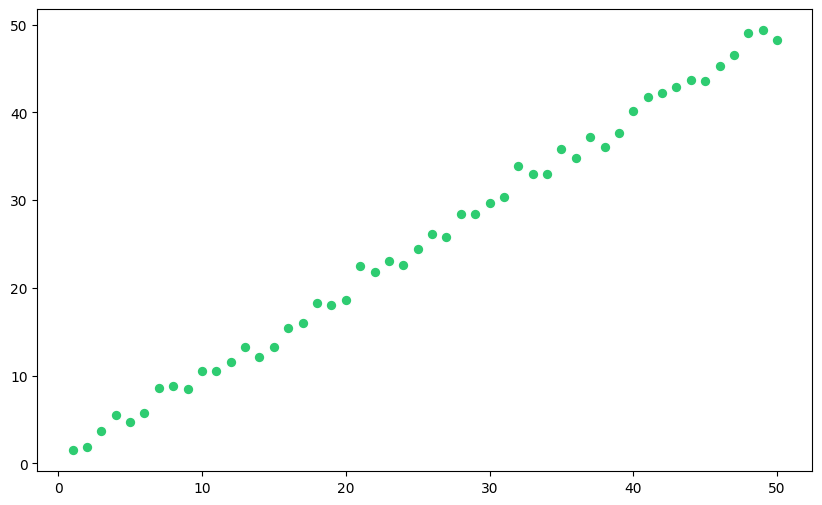

In [ ]:
# 3. Create the Plot
plt.figure(figsize=(10, 6))
plt.scatter(df['X'], df['Y'], color='#2ecc71', edgecolor='white', s=60, label='Data Points')
#plt.scatter(df['X'][25], df['Y'][25], color='#e74c3c', s=100, label='The Outlier', edgecolor='black')

In [ ]:
df.corr(method='pearson')

,X,Y
X,1.000000,0.997977
Y,0.997977,1.000000


r = 0.99 almost perfect correlation

Now lets add an outlier to the data and see what happens to the correlation

In [ ]:

# 1. Generate Data
np.random.seed(42)
x = np.linspace(1, 50, 50)
y = x + np.random.normal(0, 1, 50)
# Adding the outlier
y[25] = 150

# 2. Create DataFrame and Calculate Correlations
df = pd.DataFrame({'X': x, 'Y': y})


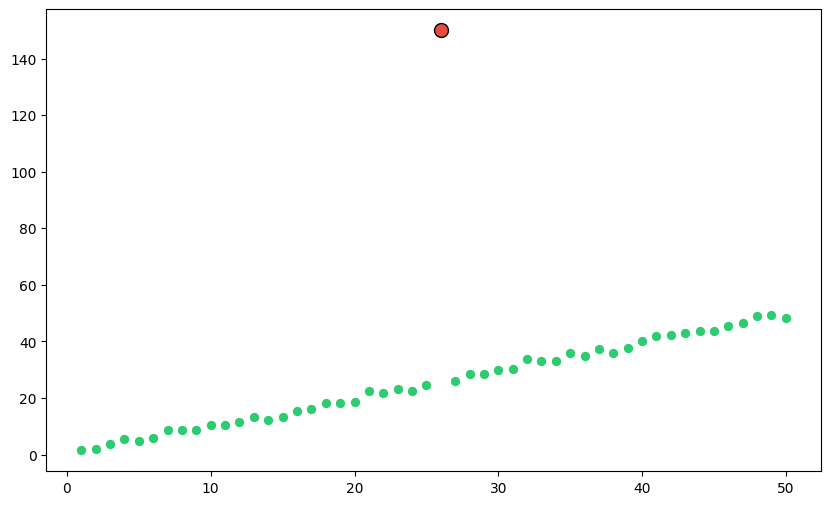

In [ ]:

plt.figure(figsize=(10, 6))
plt.scatter(df['X'], df['Y'], color='#2ecc71', edgecolor='white', s=60, label='Data Points')
plt.scatter(df['X'][25], df['Y'][25], color='#e74c3c', s=100, label='The Outlier', edgecolor='black')

In [ ]:
df.corr(method='pearson')

,X,Y
X,1.000000,0.635779
Y,0.635779,1.000000


ouu it seems like the correlation has dropped significantly, this is because Pearson's correlation is sensitive to outliers. The outlier has a disproportionate influence on the overall data, which can skew the results and lead to a much lower correlation coefficient. This is one of the reasons why it's important to check for outliers in your data before applying Pearson's correlation, as they can significantly affect the results.

Now let us see how spearman's correlation handles outliers in the same data.

In [ ]:
df.corr(method='spearman')

,X,Y
X,1.000000,0.969364
Y,0.969364,1.000000


spearmans correlation is more robust to outliers because it uses the rank of the data rather than the actual values. This means that even if there is an outlier in the data, it will not have as much of an influence on the overall correlation coefficient as it would in Pearson's correlation. In this case, we would expect to see a much higher correlation coefficient with Spearman's correlation compared to Pearson's correlation, indicating that there is still a strong relationship between the two variables despite the presence of the outlier.

**Thought**: Why Bother with Pearson's Correlation if Spearman's is more robust to outliers and even capture non-linear relationships?

<Axes: xlabel='X', ylabel='Y'>

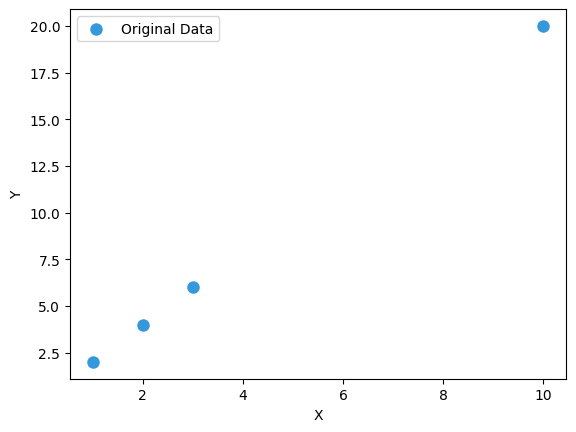

In [ ]:
import pandas as pd


data_original = {
    'X': [1, 2, 3, 10],
    'Y': [2, 4, 6, 20]
}
df1 = pd.DataFrame(data_original)

df1.plot(kind='scatter', x='X', y='Y', color='#3498db', edgecolor='white', s=100, label='Original Data')


In [ ]:
df1.corr(method='pearson')

,X,Y
X,1.0,1.0
Y,1.0,1.0


In [ ]:
df1.corr(method='spearman')

,X,Y
X,1.0,1.0
Y,1.0,1.0


<Axes: xlabel='X', ylabel='Y'>

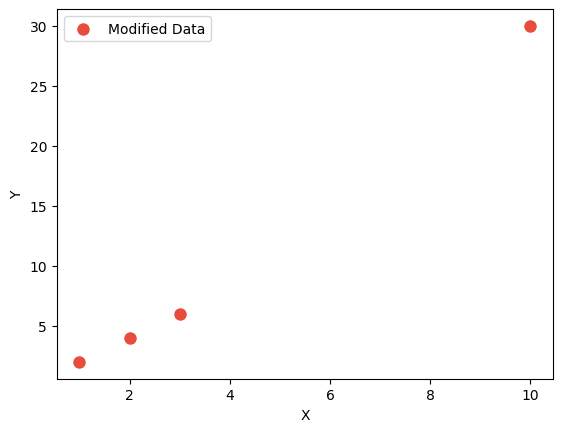

In [ ]:
data_modified = {
    'X': [1, 2, 3, 10],
    'Y': [2, 4, 6, 30] # We changed 20 to 30
}
df2 = pd.DataFrame(data_modified)
df2.plot(kind='scatter', x='X', y='Y', color='#e74c3c', edgecolor='white', s=100, label='Modified Data')

In [ ]:
df2.corr(method="spearman")

,X,Y
X,1.0,1.0
Y,1.0,1.0


In [ ]:
df2.corr(method='pearson')

,X,Y
X,1.000000,0.997083
Y,0.997083,1.000000


Pearson's correlation was able to detect a minor deviation from linearity - displaying the power of Pearson's correlation in capturing subtle linear relationships that Spearman's might miss due to its focus on ranks rather than actual values.

# Overall

![image-2.png](attachment:image-2.png)

## Capturing non-linear relationships with Beyond Spearman's Correlation

whilst spearmans correlation is more robust to outliers and can capture monotonic relationships, it still may not capture more complex non-linear relationships. In such cases, we can use other methods like **Phi-k** which is designed to capture both linear and non-linear relationships between variables, making it a powerful tool for feature selection in machine learning.

# Features Selection - Categorical vs Categorical (Chi-Squared Test)

- We cannot use correlations to identify relationships between two categorical variables, as correlations are designed for continuous data. Instead, we can use other statistical methods such as the Chi-Square test  strength of association between two categorical variables.

In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency

# Data construction
placebo = [['Placebo', 'Improved']] * 45 + [['Placebo', 'No Change']] * 55
low_dose = [['Low Dose', 'Improved']] * 55 + [['Low Dose', 'No Change']] * 45
high_dose = [['High Dose', 'Improved']] * 70 + [['High Dose', 'No Change']] * 30

df = pd.DataFrame(placebo + low_dose + high_dose, columns=['Group', 'Outcome'])

In [ ]:
df.head()

,Group,Outcome
0,Placebo,Improved
1,Placebo,Improved
2,Placebo,Improved
3,Placebo,Improved
4,Placebo,Improved


In [ ]:
# Create the summary table
contingency_table = pd.crosstab(df['Group'], df['Outcome'])

# Run Chi-Squared Test
chi2, p, dof, expected = chi2_contingency(contingency_table)

print("Contingency Table:")
print(contingency_table)

Contingency Table:
Outcome    Improved  No Change
Group                         
High Dose        70         30
Low Dose         55         45
Placebo          45         55


In [ ]:
print(f"\nUnivariate P-value: {p:.4f}")


Univariate P-value: 0.0016


## Interpretation

 The p-value is your "Yes/No" switch for the univariate stage.

If p<0.05: The relationship is "Statistically Significant." You have successfully detected a signal that is unlikely to be random noise.

The Interpretation: You conclude that dosage makes a difference. The distribution of "Improved" vs "No Change" is not the same across the three groups.

# Features Selection - Continuous vs Categorical

Carrying out the F-test (ANOVA) to compare the means of the "Income" feature between the two groups defined by the "Default" variable.

![image.png](attachment:image.png)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_selection import f_classif

# 1. Generate 100 samples
np.random.seed(42)
n_samples = 100

# Generate random incomes between 20k and 150k
income = np.random.randint(20000, 150000, n_samples)

# 2. Logic: Probability of default decreases as income increases
# We'll use a threshold to make the groups distinct
def determine_default(inc):
    if inc < 60000:
        return np.random.choice([0, 1], p=[0.3, 0.7]) # High risk
    else:
        return np.random.choice([0, 1], p=[0.9, 0.1]) # Low risk

defaults = [determine_default(i) for i in income]

df = pd.DataFrame({
    'Income': income,
    'Default': defaults
})


In [ ]:
df.head()

,Income,Default
0,141958,0
1,35795,1
2,20860,1
3,123694,0
4,148106,1


In [ ]:
# 3. Run ANOVA (f_classif)
f_stat, p_val = f_classif(df[['Income']], df['Default'])

In [ ]:
print(f"Dataset Size: {len(df)}")
print(f"Average Income (No Default): ${df[df['Default']==0]['Income'].mean():,.2f}")
print(f"Average Income (Default):    ${df[df['Default']==1]['Income'].mean():,.2f}")
print("-" * 30)
print(f"F-Statistic: {f_stat[0]:.2f}")
print(f"P-Value: {p_val[0]:.10f}")

Dataset Size: 100
Average Income (No Default): $99,384.75
Average Income (Default):    $64,428.24
------------------------------
F-Statistic: 15.08
P-Value: 0.0001867416


Teacher Note: This is equivalent to a t-test when comparing two groups, but ANOVA can handle more than two groups as well.

In [ ]:
# workflow
# introduce t test again de
# introduce the version that reduces

# Multivariate Feature Selection